In [13]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt
import numpy as np

In [14]:
# Constants
IMAGE_SIZE = (224, 224)  # Target image size
BATCH_SIZE = 32  # Batch size
EPOCHS = 10  # Number of epochs

# Paths to the dataset
train_data_dir = 'dataset/train/'
validation_data_dir = 'dataset/test/'

In [15]:
# Data Augmentation for training set and rescaling for both train and validation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

validation_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)
# Data generators for training and validation
train_generator = train_datagen.flow_from_directory(
    train_data_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

validation_generator = validation_datagen.flow_from_directory(
    validation_data_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)


Found 11620 images belonging to 10 classes.
Found 2943 images belonging to 10 classes.


In [16]:
# Automatically determine the number of classes from the training generator
NUM_CLASSES = len(train_generator.class_indices)
print(f"Detected {NUM_CLASSES} classes: {train_generator.class_indices}")


Detected 10 classes: {'Brahmi (Bacopa monnieri)': 0, 'Kallurukki (Aerva lanata)': 1, 'Karisalankanni (Eclipta prostrata)': 2, 'Keezhanelli (Phyllanthus niruri)': 3, 'Kuthiraiveli (Cleome gynandra)': 4, 'Mudakathan (Cardiospermum halicacabum)': 5, 'Nilavembu  Siriyanangai (Andrographis alata  paniculata)': 6, 'Pirandai (Cissus quadrangularis)': 7, 'Sirukurinjan (Gymnema sylvestre)': 8, 'Vallarai (Centella asiatica)': 9}


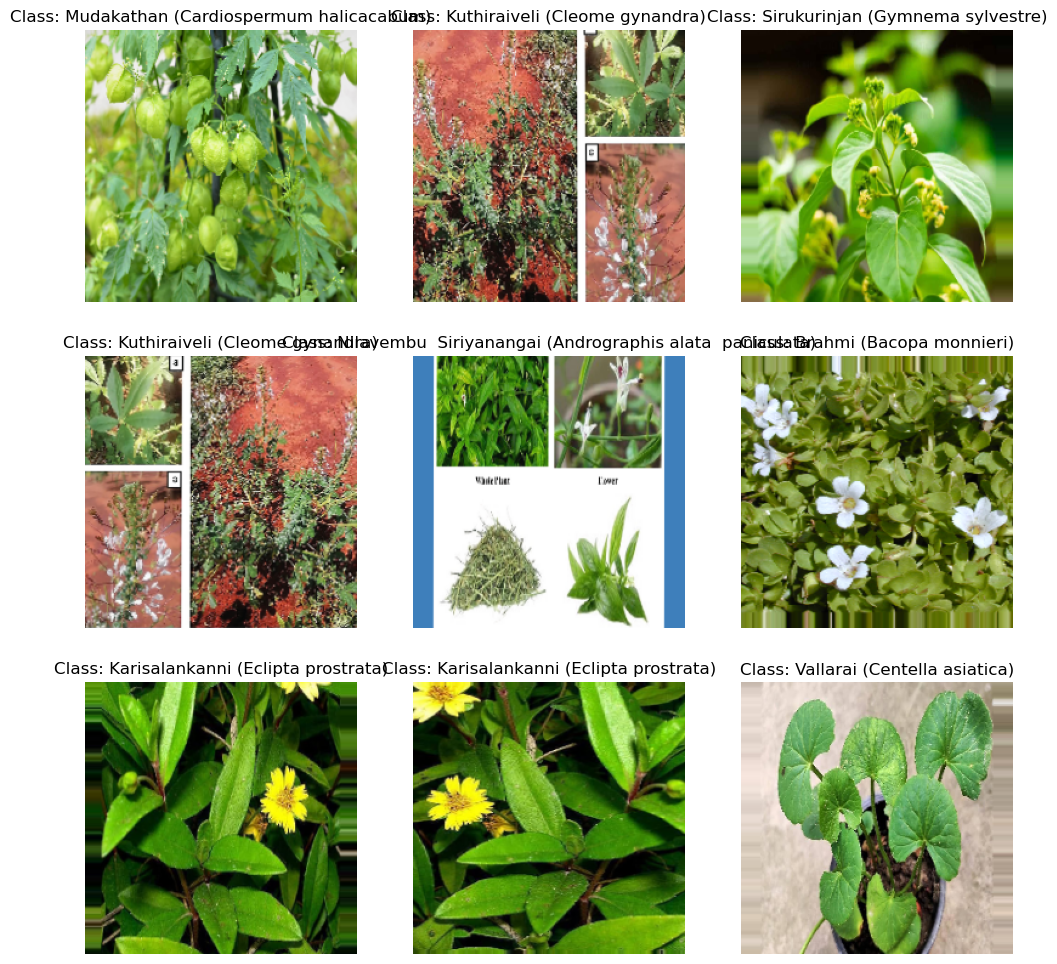

In [17]:
# Function to display some training images with class names
def show_train_images(generator, num_images=9):
    images, labels = next(generator)
    plt.figure(figsize=(12, 12))
    for i in range(num_images):
        plt.subplot(3, 3, i+1)
        plt.imshow(images[i])
        label_index = np.argmax(labels[i])
        class_name = list(generator.class_indices.keys())[label_index]
        plt.title(f'Class: {class_name}')
        plt.axis('off')
    plt.show()

# Display training images with their class names
show_train_images(train_generator)

In [18]:
# Model definition
cnn_model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)),
    MaxPooling2D((2, 2)),
    Dropout(0.25),
    
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.25),
    
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.25),
    
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(NUM_CLASSES, activation='softmax')
])

# Compile the model
cnn_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


In [19]:
# Callbacks to avoid overfitting
early_stopping_cb = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr_cb = ReduceLROnPlateau(monitor='val_loss', patience=3, factor=0.5, min_lr=1e-6)


In [20]:
# Train the model
cnn_history = cnn_model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // BATCH_SIZE,
    verbose=1,
    callbacks=[early_stopping_cb, reduce_lr_cb]
)

Epoch 1/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 827s 2s/step - accuracy: 0.8573 - loss: 0.4355 - val_accuracy: 1.0000 - val_loss: 3.2955e-04 - learning_rate: 0.0010
Epoch 2/10
  1/363 ━━━━━━━━━━━━━━━━━━━━ 4:02 671ms/step - accuracy: 0.9375 - loss: 0.1473

C:\Users\DANI\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


363/363 ━━━━━━━━━━━━━━━━━━━━ 128s 350ms/step - accuracy: 0.9375 - loss: 0.1473 - val_accuracy: 1.0000 - val_loss: 2.6071e-04 - learning_rate: 0.0010
Epoch 3/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 711s 2s/step - accuracy: 0.9888 - loss: 0.0349 - val_accuracy: 1.0000 - val_loss: 2.8523e-04 - learning_rate: 0.0010
Epoch 4/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 149s 409ms/step - accuracy: 0.9688 - loss: 0.0873 - val_accuracy: 1.0000 - val_loss: 6.9710e-04 - learning_rate: 0.0010
Epoch 5/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 691s 2s/step - accuracy: 0.9965 - loss: 0.0108 - val_accuracy: 1.0000 - val_loss: 1.6877e-06 - learning_rate: 5.0000e-04
Epoch 6/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 145s 399ms/step - accuracy: 1.0000 - loss: 7.6405e-04 - val_accuracy: 1.0000 - val_loss: 2.0023e-06 - learning_rate: 5.0000e-04
Epoch 7/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 704s 2s/step - accuracy: 0.9977 - loss: 0.0061 - val_accuracy: 1.0000 - val_loss: 3.3085e-07 - learning_rate: 5.0000e-04
Epoch 8/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 131s

In [21]:
cnn_model.predict(validation_generator)

92/92 ━━━━━━━━━━━━━━━━━━━━ 118s 1s/step


array([[1.00000000e+00, 5.77809603e-30, 1.36061419e-18, ...,
        7.33534510e-34, 3.34800349e-27, 7.60170803e-32],
       [2.64547516e-11, 4.94277521e-15, 1.38143796e-09, ...,
        2.73815788e-16, 9.99999762e-01, 1.31420625e-08],
       [2.64721950e-17, 6.77351324e-25, 1.26706516e-20, ...,
        2.05848444e-22, 2.70309643e-12, 2.95223655e-12],
       ...,
       [5.01625186e-29, 1.78646838e-33, 1.17420455e-23, ...,
        3.98228144e-38, 1.00000000e+00, 2.66647481e-18],
       [3.04171168e-28, 7.16086179e-33, 3.32559827e-21, ...,
        0.00000000e+00, 1.00000000e+00, 5.82528456e-21],
       [1.04151826e-16, 3.77854682e-20, 1.58477366e-15, ...,
        1.52221863e-17, 1.74891888e-08, 1.00000000e+00]],
      shape=(2943, 10), dtype=float32)

In [22]:
# Save the trained CNN model
cnn_model.save('cnn_model.h5')

In [23]:
# Print final accuracy for CNN
train_accuracy_cnn = cnn_history.history['accuracy'][-1]*100
val_accuracy_cnn = cnn_history.history['val_accuracy'][-1]*100
print(f"Final Training Accuracy: {train_accuracy_cnn:.2f}%")
print(f"Final Validation Accuracy: {val_accuracy_cnn:.2f}%")

Final Training Accuracy: 100.00%
Final Validation Accuracy: 100.00%


Classification Report:

                                                          precision    recall  f1-score   support

                                Brahmi (Bacopa monnieri)       1.00      1.00      1.00       303
                               Kallurukki (Aerva lanata)       1.00      1.00      1.00       217
                      Karisalankanni (Eclipta prostrata)       1.00      1.00      1.00       406
                        Keezhanelli (Phyllanthus niruri)       1.00      1.00      1.00       406
                          Kuthiraiveli (Cleome gynandra)       1.00      1.00      1.00       383
                  Mudakathan (Cardiospermum halicacabum)       1.00      1.00      1.00       147
Nilavembu  Siriyanangai (Andrographis alata  paniculata)       1.00      1.00      1.00       397
                        Pirandai (Cissus quadrangularis)       0.00      0.00      0.00         0
                        Sirukurinjan (Gymnema sylvestre)       1.00      1.00      1.00      

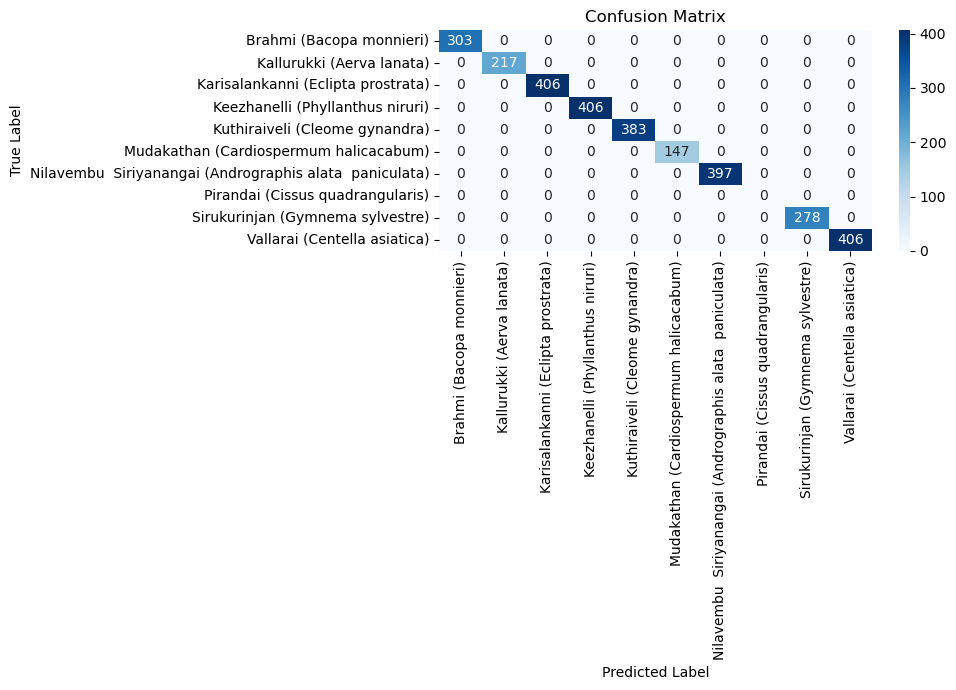

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Class labels from training generator
class_labels = list(train_generator.class_indices.keys())
num_classes = len(class_labels)

y_true = []
y_pred = []

for i in range(len(validation_generator)):
    images, labels = validation_generator[i]
    y_true.extend(np.argmax(labels, axis=1))
    predictions = cnn_model.predict(images, verbose=0)
    y_pred.extend(np.argmax(predictions, axis=1))

# Explicit labels (0 to num_classes-1)
labels = list(range(num_classes))

# Classification report
print("Classification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=labels,
    target_names=class_labels,
    zero_division=0   # avoids warning if class not predicted
))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred, labels=labels)

plt.figure(figsize=(10, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


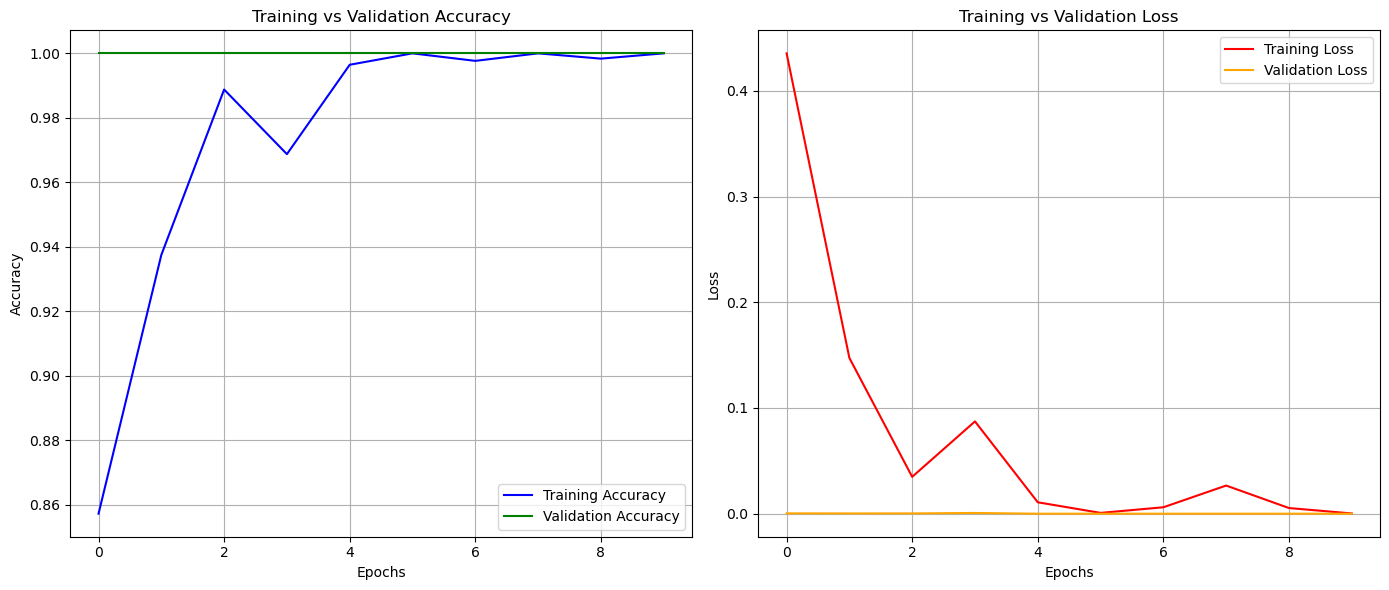

In [25]:
# Plotting training and validation metrics
def plot_metrics(history):
    train_accuracy = history.history['accuracy']
    val_accuracy = history.history['val_accuracy']
    train_loss = history.history['loss']
    val_loss = history.history['val_loss']

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    
    # Accuracy plot
    ax1.plot(train_accuracy, label='Training Accuracy', color='blue')
    ax1.plot(val_accuracy, label='Validation Accuracy', color='green')
    ax1.set_title('Training vs Validation Accuracy')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Accuracy')
    ax1.legend()
    ax1.grid(True)
    
    # Loss plot
    ax2.plot(train_loss, label='Training Loss', color='red')
    ax2.plot(val_loss, label='Validation Loss', color='orange')
    ax2.set_title('Training vs Validation Loss')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Loss')
    ax2.legend()
    ax2.grid(True)

    plt.tight_layout()
    plt.show()

# Plot metrics
plot_metrics(cnn_history)

In [ ]:
from tensorflow.keras.applications import NASNetMobile
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.models import Model
import tensorflow as tf

# Define input shape and model
input_tensor = Input(shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3))
base_model = NASNetMobile(include_top=False, weights='imagenet', input_tensor=input_tensor, pooling='avg')

# Add Dense layers on top
x = base_model.output
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
output_tensor = Dense(NUM_CLASSES, activation='softmax')(x)

nas_model = Model(inputs=base_model.input, outputs=output_tensor)

# Fine-tune the base model layers for better accuracy
for layer in base_model.layers:
    layer.trainable = True

# Compile the NAS model
nas_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), loss='categorical_crossentropy', metrics=['accuracy'])

# Train the NAS model
nas_history = nas_model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // BATCH_SIZE,
    verbose=1,
    callbacks=[early_stopping_cb, reduce_lr_cb]
)


 6774784/19993432 ━━━━━━━━━━━━━━━━━━━━ 2:08 10us/step

In [ ]:
# Save the trained NAS model
nas_model.save('nas_model.h5')

In [ ]:
# Print final accuracy for NAS model
train_accuracy_nas = nas_history.history['accuracy'][-1]*100
val_accuracy_nas = nas_history.history['val_accuracy'][-1]*100
print(f"NAS Model - Final Training Accuracy: {train_accuracy_nas:.2f}%")
print(f"NAS Model - Final Validation Accuracy: {val_accuracy_nas:.2f}%")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Get class labels
class_labels = list(train_generator.class_indices.keys())
num_classes = len(class_labels)

# Collect true and predicted labels
y_true = []
y_pred = []

validation_generator.reset()  # IMPORTANT

for i in range(len(validation_generator)):
    images, labels = validation_generator[i]
    y_true.extend(np.argmax(labels, axis=1))
    preds = nas_model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# ---- FIX HERE ----
labels = list(range(num_classes))

print("Classification Report:\n")
print(
    classification_report(
        y_true,
        y_pred,
        labels=labels,
        target_names=class_labels,
        zero_division=0
    )
)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred, labels=labels)

plt.figure(figsize=(10, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()


In [ ]:
import matplotlib.pyplot as plt

# Extract the training and validation metrics from the NAS model history
train_accuracy_nas = nas_history.history['accuracy']
val_accuracy_nas = nas_history.history['val_accuracy']
train_loss_nas = nas_history.history['loss']
val_loss_nas = nas_history.history['val_loss']

# Plotting accuracy and loss in separate subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Accuracy plot
ax1.plot(train_accuracy_nas, label='Training Accuracy', color='blue')
ax1.plot(val_accuracy_nas, label='Validation Accuracy', color='green')
ax1.set_title('NAS Model Training vs Validation Accuracy')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

# Loss plot
ax2.plot(train_loss_nas, label='Training Loss', color='red')
ax2.plot(val_loss_nas, label='Validation Loss', color='orange')
ax2.set_title('NAS Model Training vs Validation Loss')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

# Show both plots
plt.tight_layout()
plt.show()

In [ ]:
# Extract final validation accuracy for both models
final_val_accuracy_cnn = cnn_history.history['val_accuracy'][-1]
final_val_accuracy_nas = nas_history.history['val_accuracy'][-1]

# Compare the two models based on the final validation accuracy
if final_val_accuracy_nas > final_val_accuracy_cnn:
    print("NAS-based model has higher accuracy.")
else:
    print("CNN-based model has higher accuracy.")


In [ ]:
import matplotlib.pyplot as plt

# Extract final validation accuracy
final_val_accuracy_cnn = cnn_history.history['val_accuracy'][-1]
final_val_accuracy_nas = nas_history.history['val_accuracy'][-1]

models = ['CNN Model', 'NAS Model']
accuracies = [final_val_accuracy_cnn, final_val_accuracy_nas]

# Assign different colors
colors = ['#1f77b4', '#ff7f0e']  # Blue and Orange (you can pick any colors)

plt.figure(figsize=(8, 6))

bars = plt.bar(models, accuracies, color=colors)

# Title and labels
plt.title('Final Validation Accuracy Comparison', fontsize=14, pad=15)
plt.ylabel('Validation Accuracy (%)')

# Give extra headroom
plt.ylim(0, 1.1)

# Display percentage on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.03,
        f"{height * 100:.2f}%",
        ha='center',
        fontsize=12,
        fontweight='bold'
    )

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
